# TP: Sistemas de Recomendación / RL Offline (DiploDatos 2026)
## 0. Preparación del entorno

En esta primera sección configuramos el entorno directamente en Google Colab sin necesidad de usar Google Drive:
1. Clonamos el repositorio oficial de `DiploDatos/AprendizajePorRefuerzos`.
2. Instalamos las dependencias desde `2026/tp/requirements.txt`.
3. Nos posicionamos en `2026/tp`, agregamos la carpeta al `sys.path` y ejecutamos los tests unitarios junto con la evaluación de las líneas base (*baselines*).

In [1]:
import os
import sys

REPO_DIR = "/content/AprendizajePorRefuerzos"
TP_PATH = os.path.join(REPO_DIR, "2026/tp")

# Clonamos el repositorio si aún no existe en la sesión actual de Colab
if not os.path.exists(REPO_DIR):
    !git clone https://github.com/DiploDatos/AprendizajePorRefuerzos.git {REPO_DIR}
else:
    print("El repositorio ya estaba clonado en", REPO_DIR)

# Agregamos 2026/tp al sys.path y cambiamos el directorio de trabajo actual
if TP_PATH not in sys.path:
    sys.path.insert(0, TP_PATH)
os.chdir(TP_PATH)
print("Directorio de trabajo actual:", os.getcwd())

# Instalamos dependencias
!pip install -q -r requirements.txt

Cloning into '/content/AprendizajePorRefuerzos'...
remote: Enumerating objects: 1397, done.
remote: Counting objects: 100% (280/280), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 1397 (delta 198), reused 167 (delta 165), pack-reused 1117 (from 2)
Receiving objects: 100% (1397/1397), 84.15 MiB | 12.72 MiB/s, done.
Resolving deltas: 100% (703/703), done.
Updating files: 100% (90/90), done.
Directorio de trabajo actual: /content/AprendizajePorRefuerzos/2026/tp


In [2]:
# 1. Correr los tests del protocolo
!python -m pytest protocolo/tests

# 2. Evaluar las líneas base en Netflix y guardar resultados
!python -m protocolo.evaluar --dataset netflix --output outputs/baselines_netflix

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/AprendizajePorRefuerzos/2026/tp
plugins: langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0, platformdirs-4.14.3
collected 19 items                                                             

protocolo/tests/test_logs.py ....                                        [ 21%]
protocolo/tests/test_protocolo.py ...............                        [100%]

============================== 19 passed in 1.43s ==============================
                                      return  normalized  hit_rate  ndcg@10
policy          warmup group_visible                                       
group_mean      0      False          88.421       0.689     0.894    0.924
                       True           90.066       0.742     0.918    0.936
                5      False          66.735       0.705     0.904    0.923
                       Tru

## 1. Los datos y 1.3 Carga

Cargamos el dataset (`netflix` con 752 ítems o `goodreads` con 472 ítems, ambos con 8 grupos de usuarios).
Recordemos que `split_by_user` separa **usuarios completos** (90% train / 10% validación) y no interacciones individuales, evitando fuga de datos (*data leakage*).

In [3]:
from protocolo.datos import load_train, load_test, split_by_user, num_items

dataset = "netflix"  # Cambiar a "goodreads" si se desea explorar el otro dataset
n_items = num_items(dataset)

train_all = load_train(dataset)          # list[User]
train, val = split_by_user(train_all)    # 90 % / 10 % de los usuarios, por grupo
test = load_test(dataset)

print(f"Dataset: {dataset} | Cantidad total de ítems: {n_items}")
print(f"Usuarios -> Train: {len(train)} | Val: {len(val)} | Test: {len(test)}")

# Inspección del primer usuario de train
u = train[0]
print(f"\nEjemplo usuario[0] -> ID: {u.user_id} | Grupo: {u.group} | Ítems valorados: {len(u.items)}")
print(f"Primeros 5 ítems: {u.items[:5]}")
print(f"Primeros 5 ratings: {u.ratings[:5]}")

Dataset: netflix | Cantidad total de ítems: 752
Usuarios -> Train: 14400 | Val: 1600 | Test: 1600

Ejemplo usuario[0] -> ID: 0 | Grupo: 0 | Ítems valorados: 77
Primeros 5 ítems: [472  97 122 654 709]
Primeros 5 ratings: [4. 3. 4. 3. 5.]


In [6]:
import pandas as pd

# Creamos el DataFrame 'df' a partir del conjunto de train
rows = [
    (u.user_id, u.group, pos, item, r)
    for u in train
    for pos, (item, r) in enumerate(zip(u.items, u.ratings))
]
df = pd.DataFrame(rows, columns=["user_id", "group", "pos", "item", "rating"])

# Mostramos las dimensiones (shape) del DataFrame de interacciones
print("Dimensiones del dataset consolidado (filas, columnas):")
print(df.shape)

# Mostramos las primeras 5 filas (head)
print("\nPrimeras 5 filas de las interacciones:")
display(df.head())

Dimensiones del dataset consolidado (filas, columnas):
(1615959, 5)

Primeras 5 filas de las interacciones:


,user_id,group,pos,item,rating
0,0,0,0,472,4.0
1,0,0,1,97,3.0
2,0,0,2,122,4.0
3,0,0,3,654,3.0
4,0,0,4,709,5.0


In [7]:
# Mostremos la estructura para entender cómo conviven usuarios e ítems en el mismo dataset
print(f"Estructura del objeto de un usuario en el dataset actual ({dataset}):")
ejemplo_usuario = train[0]
print(f"- ID del usuario: {ejemplo_usuario.user_id}")
print(f"- Grupo al que pertenece: {ejemplo_usuario.group}")
print(f"- Ítems calificados (IDs del 0 al {n_items-1}): {ejemplo_usuario.items[:10]} ... (total {len(ejemplo_usuario.items)} ítems)")
print(f"- Calificaciones dadas a esos ítems: {ejemplo_usuario.ratings[:10]} ...")

# En resumen: No hay un dataset de ítems separado.
# Los ítems se identifican únicamente por su ID numérico dentro del historial de cada usuario.

Estructura del objeto de un usuario en el dataset actual (netflix):
- ID del usuario: 0
- Grupo al que pertenece: 0
- Ítems calificados (IDs del 0 al 751): [472  97 122 654 709 467 574 544 478 338] ... (total 77 ítems)
- Calificaciones dadas a esos ítems: [4. 3. 4. 3. 5. 4. 2. 1. 4. 5.] ...


In [8]:
import pandas as pd

# 1. Convertimos el conjunto de Validación (val) a DataFrame
val_rows = [
    (u.user_id, u.group, pos, item, r)
    for u in val
    for pos, (item, r) in enumerate(zip(u.items, u.ratings))
]
df_val = pd.DataFrame(val_rows, columns=["user_id", "group", "pos", "item", "rating"])

# 2. Convertimos el conjunto de Test (test) a DataFrame
test_rows = [
    (u.user_id, u.group, pos, item, r)
    for u in test
    for pos, (item, r) in enumerate(zip(u.items, u.ratings))
]
df_test = pd.DataFrame(test_rows, columns=["user_id", "group", "pos", "item", "rating"])

# Mostramos los resultados
print("=== CONJUNTO DE VALIDACIÓN (VAL) ===")
print(f"Shape: {df_val.shape}")
print("Head:")
display(df_val.head())

print("\n=== CONJUNTO DE TEST (TEST) ===")
print(f"Shape: {df_test.shape}")
print("Head:")
display(df_test.head())

=== CONJUNTO DE VALIDACIÓN (VAL) ===
Shape: (181653, 5)
Head:


,user_id,group,pos,item,rating
0,12,0,0,562,4.0
1,12,0,1,133,4.0
2,12,0,2,651,2.0
3,12,0,3,172,5.0
4,12,0,4,80,5.0



=== CONJUNTO DE TEST (TEST) ===
Shape: (1203200, 5)
Head:


,user_id,group,pos,item,rating
0,0,0,0,0,4.0
1,0,0,1,1,1.0
2,0,0,2,2,3.0
3,0,0,3,3,5.0
4,0,0,4,4,5.0


## 1.4 Exploración de los datos (EDA)

Antes de modelar, analizamos cómo se registraron los logs en `train` para entender la política de recolección y la estructura de los grupos:
1. **Sesgo de posición:** ¿Cambia el rating medio según el orden en que el usuario vio el ítem?
2. **Sesgo de popularidad:** ¿Los ítems más frecuentes en los logs son los mejor valorados?
3. **Distribución de ratings:** Global y desagregada por cada uno de los 8 grupos.
4. **Longitud de sesiones/historiales:** Cantidad de ítems valorados por usuario.
5. **Similitud entre grupos:** Matriz de correlación entre las valoraciones medias por ítem de cada par de grupos.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética para los gráficos
sns.set_theme(style="whitegrid")

# Armamos el DataFrame en formato largo (una fila por interacción)
rows = [
    (u.user_id, u.group, pos, item, r)
    for u in train
    for pos, (item, r) in enumerate(zip(u.items, u.ratings))
]
df = pd.DataFrame(rows, columns=["user_id", "group", "pos", "item", "rating"])

print(f"Total de interacciones en train: {len(df):,}\n")

# 1. ¿El rating medio cambia según la posición en la trayectoria?
print("--- 1. Rating medio según posición ---")
pos_bins = pd.cut(df.pos, [0, 10, 25, 50, 100, 200], right=False)
print(df.groupby(pos_bins, observed=True).rating.agg(["mean", "count"]))

# 2. ¿Los ítems que más aparecen son los mejor valorados?
print("\n--- 2. Correlación entre frecuencia de aparición y rating medio ---")
by_item = df.groupby("item").rating.agg(["mean", "count"])
print(by_item.corr())

Total de interacciones en train: 1,615,959

--- 1. Rating medio según posición ---
                mean   count
pos                         
[0, 10)     3.225611  144000
[10, 25)    3.215125  216000
[25, 50)    3.216467  333339
[50, 100)   3.216799  513106
[100, 200)  3.208684  409514

--- 2. Correlación entre frecuencia de aparición y rating medio ---
           mean     count
mean   1.000000 -0.041987
count -0.041987  1.000000


--- 3. Estadísticas de ratings por grupo ---
           mean       std   count
group                            
0      3.774578  1.155817  199661
1      3.386843  1.271243  203160
2      3.119334  1.221177  201552
3      2.836923  1.282207  202536
4      4.155834  0.994119  201156
5      3.008083  1.292581  204881
6      3.339532  1.270074  199666
7      2.122647  1.145488  203347

--- 4. Cantidad de ítems por usuario ---
count    14400.000000
mean       112.219375
std         50.655126
min         25.000000
25%         69.000000
50%        112.000000
75%        156.000000
max        200.000000
dtype: float64


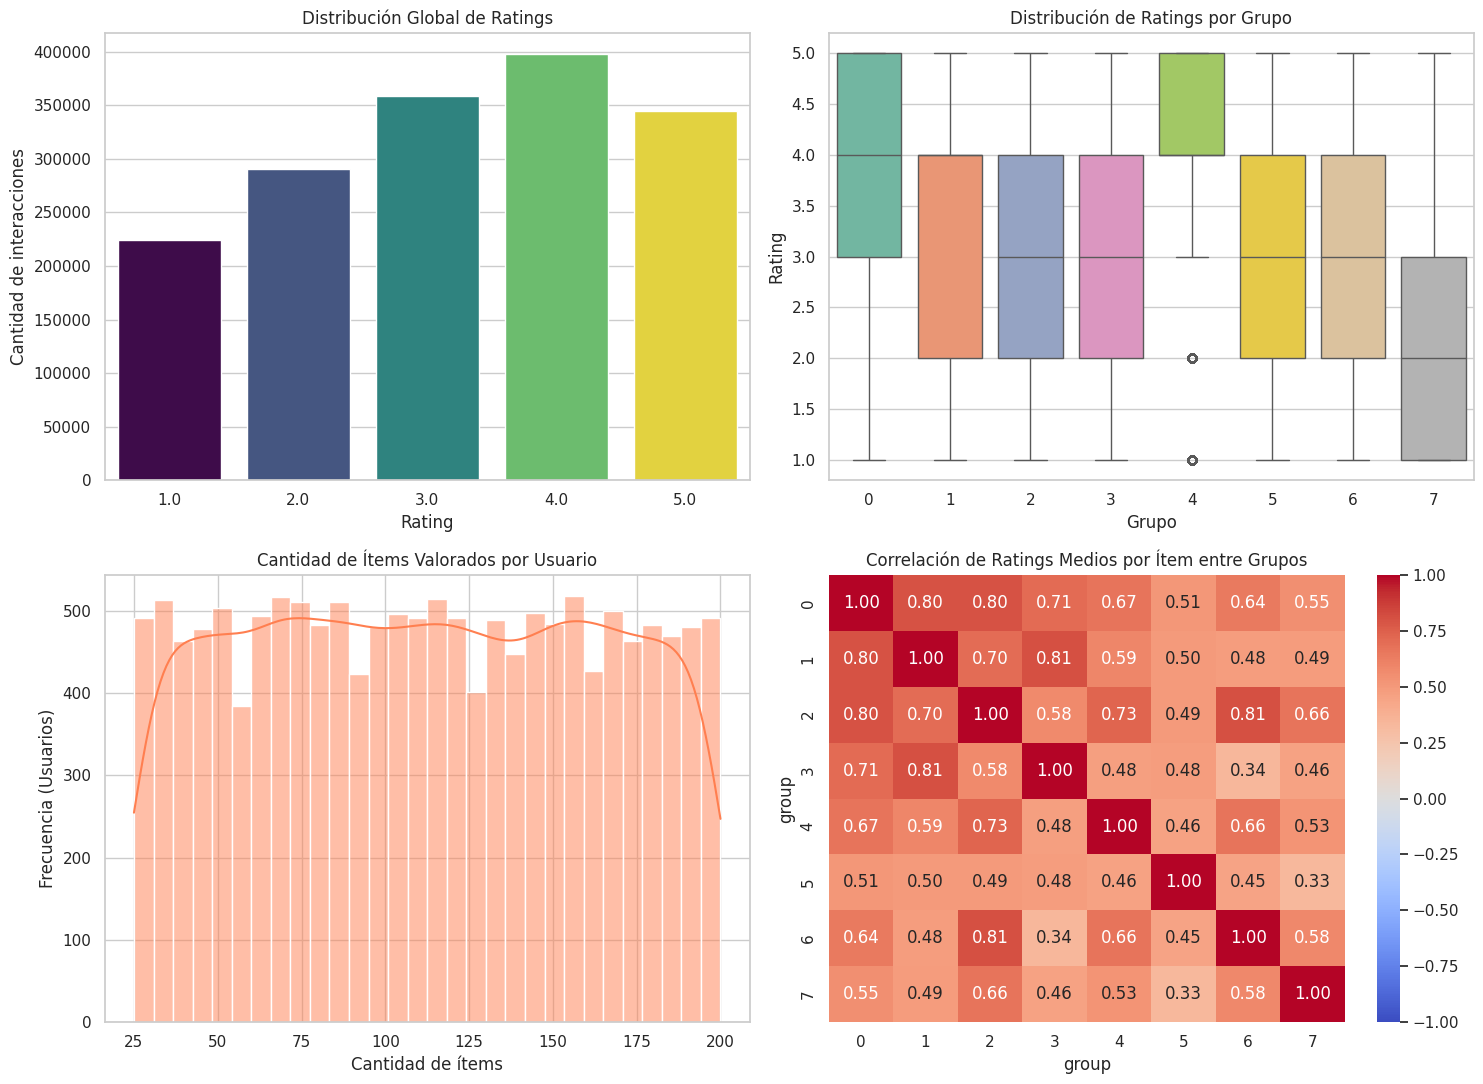

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# --- 3A. Distribución global de ratings ---
rating_counts = df["rating"].value_counts().sort_index()
sns.barplot(x=rating_counts.index, y=rating_counts.values, ax=axes[0, 0], palette="viridis", hue=rating_counts.index, legend=False)
axes[0, 0].set_title("Distribución Global de Ratings")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Cantidad de interacciones")

# --- 3B. Distribución de ratings por grupo (Media y Boxplot) ---
group_stats = df.groupby("group")["rating"].agg(["mean", "std", "count"])
print("--- 3. Estadísticas de ratings por grupo ---")
print(group_stats)

sns.boxplot(data=df, x="group", y="rating", ax=axes[0, 1], palette="Set2", hue="group", legend=False)
axes[0, 1].set_title("Distribución de Ratings por Grupo")
axes[0, 1].set_xlabel("Grupo")
axes[0, 1].set_ylabel("Rating")

# --- 4. Cantidad de ítems por usuario ---
items_per_user = df.groupby("user_id").size()
print("\n--- 4. Cantidad de ítems por usuario ---")
print(items_per_user.describe())

sns.histplot(items_per_user, bins=30, kde=True, ax=axes[1, 0], color="coral")
axes[1, 0].set_title("Cantidad de Ítems Valorados por Usuario")
axes[1, 0].set_xlabel("Cantidad de ítems")
axes[1, 0].set_ylabel("Frecuencia (Usuarios)")

# --- 5. Correlación entre grupos (gustos por ítem) ---
# Creamos matriz ítems x grupos con el rating medio de cada ítem en cada grupo
item_group_matrix = df.pivot_table(index="item", columns="group", values="rating", aggfunc="mean")
group_corr = item_group_matrix.corr()

sns.heatmap(group_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title("Correlación de Ratings Medios por Ítem entre Grupos")

plt.tight_layout()
plt.show()

### Conclusiones de la Exploración (Completar tras ejecutar)

* **Sesgo de posición:** Observamos que el rating medio no varia significativamente segun la posicion.
* **Sesgo de popularidad:** Los ítems más frecuentes en el historial de entrenamiento no son los mejor valorados ni los peores; aparecen con frecuencias similares independientemente de su calidad.
* **Comportamiento de los grupos:**
El grupo 7 es el más exigente.
Los grupos 0 y 4 suelen dar los puntajes más altos. Aunque pareciera que el comportamiento del 4 es dar valores más extremos (vemos algunos valores muy bajos en el boxplot).
* **Longitud de historiales:** *(Verificar el rango mínimo y máximo de ítems por usuario, esperado entre 25 y 200).*

--- Top 5 ítems UNIVERSALES (alta media, bajo desvío entre grupos) ---
      media_global  std_entre_grupos  min_grupo  max_grupo     rango
item                                                                
623       4.584864          0.229267   4.162630   4.876761  0.714131
285       4.572379          0.232993   4.170213   4.846429  0.676216
293       4.570352          0.251703   4.067164   4.847751  0.780587
144       4.552707          0.189159   4.275093   4.819188  0.544095
401       4.522289          0.299224   3.869565   4.801498  0.931933

--- Top 5 ítems POLARIZANTES (mayor diferencia entre grupos) ---
      media_global  std_entre_grupos  min_grupo  max_grupo     rango
item                                                                
211       2.813221          1.126303   1.335793   4.472527  3.136734
698       2.846742          1.123289   1.413534   4.310606  2.897072
713       3.209121          1.118617   1.615672   4.581818  2.966147
460       3.210287          1.11691

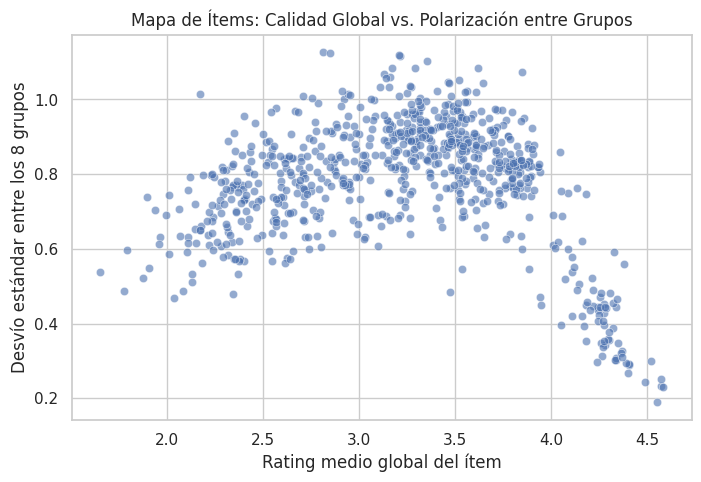

In [11]:
# --- 6. Ítems universales vs. polarizantes (para Cold Start y exploración) ---
item_stats_across_groups = pd.DataFrame({
    "media_global": item_group_matrix.mean(axis=1),
    "std_entre_grupos": item_group_matrix.std(axis=1),
    "min_grupo": item_group_matrix.min(axis=1),
    "max_grupo": item_group_matrix.max(axis=1),
})
item_stats_across_groups["rango"] = item_stats_across_groups["max_grupo"] - item_stats_across_groups["min_grupo"]

print("--- Top 5 ítems UNIVERSALES (alta media, bajo desvío entre grupos) ---")
print(item_stats_across_groups.sort_values(by=["media_global", "std_entre_grupos"], ascending=[False, True]).head(5))

print("\n--- Top 5 ítems POLARIZANTES (mayor diferencia entre grupos) ---")
print(item_stats_across_groups.sort_values(by="std_entre_grupos", ascending=False).head(5))

# --- 7. Cobertura por par (grupo, ítem) y ruido intra-grupo ---
counts_per_cell = df.groupby(["group", "item"])["rating"].count()
std_intra_group = df.groupby(["group", "item"])["rating"].std()

print(f"\nObservaciones por par (grupo, ítem) -> Mín: {counts_per_cell.min()} | Media: {counts_per_cell.mean():.1f} | Máx: {counts_per_cell.max()}")
print(f"Ruido intra-grupo promedio (std dentro del mismo grupo e ítem): {std_intra_group.mean():.3f}")

# Gráfico de dispersión: Media global vs. Desvío entre grupos
plt.figure(figsize=(8, 5))
sns.scatterplot(data=item_stats_across_groups, x="media_global", y="std_entre_grupos", alpha=0.6)
plt.title("Mapa de Ítems: Calidad Global vs. Polarización entre Grupos")
plt.xlabel("Rating medio global del ítem")
plt.ylabel("Desvío estándar entre los 8 grupos")
plt.show()